# Unemployment Analysis with Python
### Oasis Infobyte Data Science Internship — Task 2

**Objective:** Explore unemployment estimates across Indian states/territories, monthly changes, employment and labour participation, and differences around the 2020 COVID-19 period.

This is an **exploratory, descriptive analysis**, not a prediction project. It does not require a model or an accuracy score. Every finding below will be based on executed code and observed data.

## 1. Import libraries
- **Pandas:** load, clean, and group table data.
- **NumPy:** numerical checks and calculations.
- **Matplotlib / Seaborn:** clearly labelled charts.
- **Pathlib (`Path`):** work with file paths across operating systems.

Run the notebook from top to bottom. In Jupyter, `Shift + Enter` runs the selected cell.

In [13]:
# pandas handles tables; NumPy supports numerical calculations.
import pandas as pd
import numpy as np

# Matplotlib and Seaborn create charts; Path handles file paths.
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Use one readable style for every chart in this project.
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.figsize": (11, 5), "axes.titlesize": 15,
                     "axes.labelsize": 12, "font.size": 11})
pd.set_option("display.max_columns", None)

print("Library versions:", {"pandas": pd.__version__, "numpy": np.__version__,
                           "matplotlib": plt.matplotlib.__version__, "seaborn": sns.__version__})

Library versions: {'pandas': '3.0.3', 'numpy': '2.4.6', 'matplotlib': '3.11.0', 'seaborn': '0.13.2'}


## 2. Load and inspect the dataset

No unemployment dataset was found in the searched project/download locations. A local copy of **`Unemployment_Rate_upto_11_2020.csv`** was obtained from [Gokul Raj Kuppan's Kaggle dataset](https://www.kaggle.com/datasets/gokulrajkmv/unemployment-in-india), version 5. The publisher attributes the data to [CMIE](https://unemploymentinindia.cmie.com/).

**Source caution:** This is a commonly used educational copy, not independently verified original survey microdata. The publisher's `Estimated Employed` description is inconsistent with the large values in the file: we treat it as an estimated count, **not an employment rate**, and note the incomplete unit documentation.

**Sharing caution:** Kaggle lists the license as *Other (specified in description)*, without a clear redistribution grant. Keep the CSV local; the project ignores CSV files in Git and provides download instructions instead.

The loader below works from the project folder, the OIBSIP repository root, or this original notebook location. It stops with a helpful message if the expected CSV is missing. We keep `raw_df` unchanged so we can compare before and after cleaning.

`head()` and `tail()` show the first and last records. `shape` gives rows and columns; `dtypes`, missing-value counts, duplicates, and `describe()` reveal potential cleaning needs. **The filename is not evidence of the actual date range.**

In [2]:
# Look for the verified CSV in a few sensible project locations.
csv_name = "Unemployment_Rate_upto_11_2020.csv"
candidate_folders = [Path.cwd(),
                     Path.cwd() / "DataScience-Task2-UnemploymentAnalysis",
                     Path.cwd() / "OIBSIP" / "DataScience-Task2-UnemploymentAnalysis"]
project_dir = next((folder for folder in candidate_folders
                    if (folder / "dataset" / csv_name).is_file()), None)
if project_dir is None:
    raise FileNotFoundError("Download the Kaggle CSV and place it in the project's dataset folder. See dataset/README.md.")

csv_path = project_dir / "dataset" / csv_name
raw_df = pd.read_csv(csv_path)
print("Dataset:", csv_path.name)
print("Rows and columns:", raw_df.shape)
print("Column names:", raw_df.columns.tolist())
print("\nFirst five rows:")
display(raw_df.head())
print("Last five rows:")
display(raw_df.tail())
print("Data types and missing values:")
display(pd.DataFrame({"dtype": raw_df.dtypes.astype(str),
                      "missing_values": raw_df.isna().sum()}))
print("Exact duplicate rows:", raw_df.duplicated().sum())
print("Statistical summary (including text columns):")
display(raw_df.describe(include="all").T)

Dataset: Unemployment_Rate_upto_11_2020.csv
Rows and columns: (267, 9)
Column names: ['Region', ' Date', ' Frequency', ' Estimated Unemployment Rate (%)', ' Estimated Employed', ' Estimated Labour Participation Rate (%)', 'Region.1', 'longitude', 'latitude']

First five rows:


,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Region.1,longitude,latitude
0,Andhra Pradesh,31-01-2020,M,5.48,16635535,41.02,South,15.9129,79.74
1,Andhra Pradesh,29-02-2020,M,5.83,16545652,40.90,South,15.9129,79.74
2,Andhra Pradesh,31-03-2020,M,5.79,15881197,39.18,South,15.9129,79.74
3,Andhra Pradesh,30-04-2020,M,20.51,11336911,33.10,South,15.9129,79.74
4,Andhra Pradesh,31-05-2020,M,17.43,12988845,36.46,South,15.9129,79.74


Last five rows:


,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Region.1,longitude,latitude
262,West Bengal,30-06-2020,M,7.29,30726310,40.39,East,22.9868,87.855
263,West Bengal,31-07-2020,M,6.83,35372506,46.17,East,22.9868,87.855
264,West Bengal,31-08-2020,M,14.87,33298644,47.48,East,22.9868,87.855
265,West Bengal,30-09-2020,M,9.35,35707239,47.73,East,22.9868,87.855
266,West Bengal,31-10-2020,M,9.98,33962549,45.63,East,22.9868,87.855


Data types and missing values:


,dtype,missing_values
Region,str,0
Date,str,0
Frequency,str,0
Estimated Unemployment Rate (%),float64,0
Estimated Employed,int64,0
Estimated Labour Participation Rate (%),float64,0
Region.1,str,0
longitude,float64,0
latitude,float64,0


Exact duplicate rows: 0
Statistical summary (including text columns):


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Region,267,27,Andhra Pradesh,10,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Date,267,10,31-03-2020,27,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Frequency,267,1,M,267,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Estimated Unemployment Rate (%),267.0,NaN,NaN,NaN,12.236929,10.803283,0.5,4.845,9.65,16.755,75.85
Estimated Employed,267.0,NaN,NaN,NaN,13962105.722846,13366318.359733,117542.0,2838930.5,9732417.0,21878686.0,59433759.0
Estimated Labour Participation Rate (%),267.0,NaN,NaN,NaN,41.681573,7.845419,16.77,37.265,40.39,44.055,69.69
Region.1,267,5,North,79,NaN,NaN,NaN,NaN,NaN,NaN,NaN
longitude,267.0,NaN,NaN,NaN,22.826048,6.270731,10.8505,18.1124,23.6102,27.2784,33.7782
latitude,267.0,NaN,NaN,NaN,80.532425,5.831738,71.1924,76.0856,79.0193,85.2799,92.9376


## 3. Clean and validate the data

### Decisions before cleaning
1. Work on `df = raw_df.copy()` to preserve the original data.
2. Strip spaces from headers and text values. Rename the inspected state field `Region` to **`State`**, and Pandas' second-header name `Region.1` to **`Geographic Region`**.
3. Parse dates with the observed **day-month-year** format (`%d-%m-%Y`). Convert the three analysis measures explicitly to numeric types.
4. Check for conversion failures, invalid percentages, negative employment estimates, duplicates, and repeated state-month keys. Stop rather than silently discard unexpected problems.
5. Inspect **missing records** separately from missing cells: a complete row does not mean every state has every month.
6. Retain unusually high but valid unemployment rates; extreme values alone are not a reason to delete observations.

The coordinate headers look questionable (for example, Andhra Pradesh has `longitude=15.9129`, `latitude=79.74`, suggesting reversed labels). We will inspect coordinate ranges, retain the raw fields, and **not use them for maps or analytical correlations**. We cannot verify geographic metadata from this file alone.

A percentage is a rate; a **percentage-point difference** is the subtraction of two rates. These are different from relative percentage changes.

In [3]:
df = raw_df.copy()
df.columns = df.columns.str.strip()
for column in df.select_dtypes(include=["object", "string"]).columns:
    df[column] = df[column].str.strip()

df = df.rename(columns={"Region": "State", "Region.1": "Geographic Region"})
rate_col = "Estimated Unemployment Rate (%)"
employment_col = "Estimated Employed"
participation_col = "Estimated Labour Participation Rate (%)"
measure_cols = [rate_col, employment_col, participation_col]

# Explicit formats prevent ambiguous date interpretation.
df["Date"] = pd.to_datetime(df["Date"], format="%d-%m-%Y", errors="coerce")
for column in measure_cols:
    df[column] = pd.to_numeric(df[column], errors="coerce")
if df.isna().any().any():
    raise ValueError("Missing values or conversion failures detected. Inspect them before continuing.")

invalid_rates = ~df[[rate_col, participation_col]].apply(lambda values: values.between(0, 100))
if invalid_rates.any().any() or (df[employment_col] < 0).any():
    raise ValueError("A percentage is outside 0–100 or employment is negative. Investigate the source.")
if not np.isfinite(df[measure_cols].to_numpy()).all():
    raise ValueError("A numerical measure contains an infinite value.")

print("Exact duplicates after trimming:", df.duplicated().sum())
print("Repeated state-date keys:", df.duplicated(["State", "Date"]).sum())
assert not df.duplicated(["State", "Date"]).any(), "Investigate repeated state-date records."
assert df.groupby("State")["Geographic Region"].nunique().eq(1).all()
assert df["Frequency"].eq("M").all(), "This analysis expects the observed monthly frequency."
assert df["Date"].dt.is_month_end.all()

df = df.sort_values(["Date", "State"]).reset_index(drop=True)
df["Month"] = df["Date"].dt.to_period("M").dt.to_timestamp()

print("Actual date range:", df["Date"].min().date(), "to", df["Date"].max().date())
print("States/territories:", df["State"].nunique())
print("Geographic regions:", sorted(df["Geographic Region"].unique()))
print("Unique frequency values:", df["Frequency"].unique().tolist())
print("Cleaned dtypes and missingness:")
display(pd.DataFrame({"dtype": df.dtypes.astype(str), "missing": df.isna().sum()}))

# Expose absent state-month records instead of inventing values for them.
all_months = pd.date_range(df["Month"].min(), df["Month"].max(), freq="MS")
coverage = pd.crosstab(df["State"], df["Month"]).reindex(columns=all_months, fill_value=0)
missing_records = (coverage.eq(0).stack().loc[lambda values: values]
                   .rename("Missing").reset_index())
missing_records.columns = ["State", "Month", "Missing"]
print("Absent state-month records:")
display(missing_records[["State", "Month"]])
print("Coordinate ranges (original labels retained, not used in analysis):")
display(df[["longitude", "latitude"]].agg(["min", "max"]))
print("Cleaned sample:")
display(df.head())

Exact duplicates after trimming: 0
Repeated state-date keys: 0
Actual date range: 2020-01-31 to 2020-10-31
States/territories: 27
Geographic regions: ['East', 'North', 'Northeast', 'South', 'West']
Unique frequency values: ['M']
Cleaned dtypes and missingness:


,dtype,missing
State,str,0
Date,datetime64[us],0
Frequency,str,0
Estimated Unemployment Rate (%),float64,0
Estimated Employed,int64,0
Estimated Labour Participation Rate (%),float64,0
Geographic Region,str,0
longitude,float64,0
latitude,float64,0
Month,datetime64[us],0


Absent state-month records:


,State,Month
0,Jammu & Kashmir,2020-04-01
1,Sikkim,2020-01-01
2,Sikkim,2020-02-01


Coordinate ranges (original labels retained, not used in analysis):


,longitude,latitude
min,10.8505,71.1924
max,33.7782,92.9376


Cleaned sample:


,State,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Geographic Region,longitude,latitude,Month
0,Andhra Pradesh,2020-01-31,M,5.48,16635535,41.02,South,15.9129,79.7400,2020-01-01
1,Assam,2020-01-31,M,4.66,13051904,52.98,Northeast,26.2006,92.9376,2020-01-01
2,Bihar,2020-01-31,M,10.61,26397671,37.72,East,25.0961,85.3131,2020-01-01
3,Chhattisgarh,2020-01-31,M,9.65,8552172,43.08,West,21.2787,81.8661,2020-01-01
4,Delhi,2020-01-31,M,22.23,5805284,47.79,North,28.7041,77.1025,2020-01-01


### Cleaning results and scope

- **267 records retained:** no missing cells, invalid analysis values, exact duplicates, or repeated state-date keys were found. No imputation or row deletion was justified.
- Actual dates: **31 January–31 October 2020**, despite `upto_11_2020` in the filename.
- Coverage: **27 states/territories**, **5 geographic groups**, **10 months**. This is not complete coverage of every Indian state/territory.
- Missing state-month records: **Sikkim, January and February; Jammu & Kashmir, April**. They remain absent rather than being replaced with invented zeros or averages.
- There is **no urban/rural column**, so this CSV cannot support an urban-versus-rural analysis. `Geographic Region` means East/North/Northeast/South/West, not urban/rural.
- Coordinate ranges reinforce the suspected reversed labels. They remain unchanged and unused.

## 4. Exploratory data analysis

`groupby()` collects rows with the same state, region, or month. `agg()` calculates summaries such as mean, median, minimum, maximum, and number of observations.

**How to read averages:** Overall statistics describe the observed **state-month records**, not individuals. State means average the available months; regional means below give each observed state mean equal weight. Monthly means give each available state one vote. No population or labour-force weights are available, so none of these should be described as India's official unemployment rate.

We also calculate a **complete-cohort monthly mean** using the 25 states/territories observed in all 10 months, to check the effect of changing coverage. The main tables retain all observations.

`Estimated Employed` is analysed as a source estimated count. Differences between states also reflect their different sizes. Participation and unemployment are distinct percentage measures.

In [4]:
print("Overall numerical statistics (state-month observations):")
display(df[measure_cols].describe().round(2))

state_summary = (df.groupby("State").agg(
    geographic_region=("Geographic Region", "first"),
    observations=(rate_col, "size"),
    mean_unemployment_pct=(rate_col, "mean"),
    median_unemployment_pct=(rate_col, "median"),
    min_unemployment_pct=(rate_col, "min"),
    max_unemployment_pct=(rate_col, "max"),
    mean_estimated_employed=(employment_col, "mean"),
    mean_participation_pct=(participation_col, "mean"))
    .sort_values("mean_unemployment_pct", ascending=False))
print("State/territory comparisons:")
display(state_summary.round(2))

# First average each state's months; then average states within each region.
regional_summary = (state_summary.groupby("geographic_region").agg(
    states=("mean_unemployment_pct", "size"),
    mean_state_unemployment_pct=("mean_unemployment_pct", "mean"),
    mean_state_participation_pct=("mean_participation_pct", "mean"))
    .sort_values("mean_state_unemployment_pct", ascending=False))
print("Geographic region comparisons (equal weight per state):")
display(regional_summary.round(2))

monthly_summary = df.groupby("Month").agg(
    observed_states=("State", "nunique"),
    mean_unemployment_pct=(rate_col, "mean"),
    median_unemployment_pct=(rate_col, "median"),
    mean_participation_pct=(participation_col, "mean"),
    sum_estimated_employed=(employment_col, "sum"))
complete_states = coverage.index[coverage.eq(1).all(axis=1)].tolist()
balanced_df = df[df["State"].isin(complete_states)].copy()
monthly_summary["complete_cohort_unemployment_pct"] = balanced_df.groupby("Month")[rate_col].mean()
print("Monthly comparisons:")
display(monthly_summary.round(2))
print("Number of states in the complete cohort:", len(complete_states))
print("Highest individual unemployment observations:")
display(df.nlargest(5, rate_col)[["State", "Date", rate_col]])

# Only socioeconomic measures: do not correlate IDs, dates, or suspect coordinates.
correlation = df[measure_cols].corr(method="pearson")
print("Pooled Pearson correlations (state-month records):")
display(correlation.round(3))

Overall numerical statistics (state-month observations):


,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%)
count,267.00,267.00,267.00
mean,12.24,13962105.72,41.68
std,10.80,13366318.36,7.85
min,0.50,117542.00,16.77
25%,4.84,2838930.50,37.26
50%,9.65,9732417.00,40.39
75%,16.76,21878686.00,44.06
max,75.85,59433759.00,69.69


State/territory comparisons:


,geographic_region,observations,mean_unemployment_pct,median_unemployment_pct,min_unemployment_pct,max_unemployment_pct,mean_estimated_employed,mean_participation_pct
State,,,,,,,,
Haryana,North,10,27.48,26.24,19.68,43.22,6844059.00,42.10
Tripura,Northeast,10,25.06,24.82,11.57,41.23,1397291.60,57.85
Jharkhand,East,10,19.54,11.20,7.63,59.23,8770642.40,40.36
Bihar,East,10,19.47,13.11,9.82,46.64,23606828.00,37.17
Delhi,North,10,18.41,16.86,6.27,42.27,4632821.90,35.86
Puducherry,South,10,17.94,5.62,0.58,75.85,365262.90,35.92
Jammu & Kashmir,North,9,16.48,16.17,10.88,21.08,3310031.67,37.89
Himachal Pradesh,North,10,16.07,16.31,2.20,26.95,2033884.90,40.25
Rajasthan,North,10,15.87,15.54,10.97,24.15,19731752.20,40.59


Geographic region comparisons (equal weight per state):


...

,observed_states,mean_unemployment_pct,median_unemployment_pct,mean_participation_pct,sum_estimated_employed,complete_cohort_unemployment_pct
Month,,,,,,
2020-01-01,26,9.20,6.24,44.63,406567194,8.72
2020-02-01,26,9.27,6.99,44.18,402694917,8.81
2020-03-01,27,10.78,8.23,43.75,392543817,10.08
2020-04-01,26,22.24,17.56,35.30,274825174,23.03
2020-05-01,27,23.24,19.97,39.65,310699661,23.37
2020-06-01,27,10.91,9.71,41.20,374149633,10.89
2020-07-01,27,9.83,7.63,42.27,389286580,10.01
2020-08-01,27,10.31,9.76,42.39,389584135,10.20
2020-09-01,27,8.71,6.40,41.97,393871643,8.53


Number of states in the complete cohort: 25
Highest individual unemployment observations:


,State,Date,Estimated Unemployment Rate (%)
95,Puducherry,2020-04-30,75.85
115,Jharkhand,2020-05-31,59.23
122,Puducherry,2020-05-31,58.19
99,Tamil Nadu,2020-04-30,49.83
88,Jharkhand,2020-04-30,47.09


Pooled Pearson correlations (state-month records):


,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%)
Estimated Unemployment Rate (%),1.000,-0.245,-0.074
Estimated Employed,-0.245,1.000,-0.048
Estimated Labour Participation Rate (%),-0.074,-0.048,1.000


## 5. Visualizations

Each chart answers a different question and uses the actual cleaned observations. Charts are displayed inside the notebook; **no image files are exported**.

1. **Distribution:** Are most unemployment observations low, high, or spread widely? A histogram counts records in rate ranges; the dashed line marks the median.
2. **Top 10:** Which states/territories have the highest mean across their observed months?
3. **State trends:** How did three selected major states—Maharashtra, Tamil Nadu, and Uttar Pradesh—change over time? They were selected for illustration, not because they are the highest-ranked states.
4. **Monthly averages:** Compare all available states with the fixed 25-state complete cohort. Neither series is population-weighted.
5. **Correlation:** Pearson's coefficient ranges from −1 to +1. Values near zero indicate weak linear association; they do not rule out nonlinear or state-specific patterns. Employment is a count, not a percentage. Repeated state-month observations and state size can influence pooled correlations.
6. **Regional differences:** Each state's period average has equal weight within its geographic group.
7. **Participation and employment trends:** Use the fixed complete cohort to avoid changes caused solely by absent records. Aggregated employment counts cover this cohort only, not all of India.

Rate axes use **percent (%)**, employment uses **millions of estimated people**, and bar charts start at zero. High observations are retained rather than hidden.

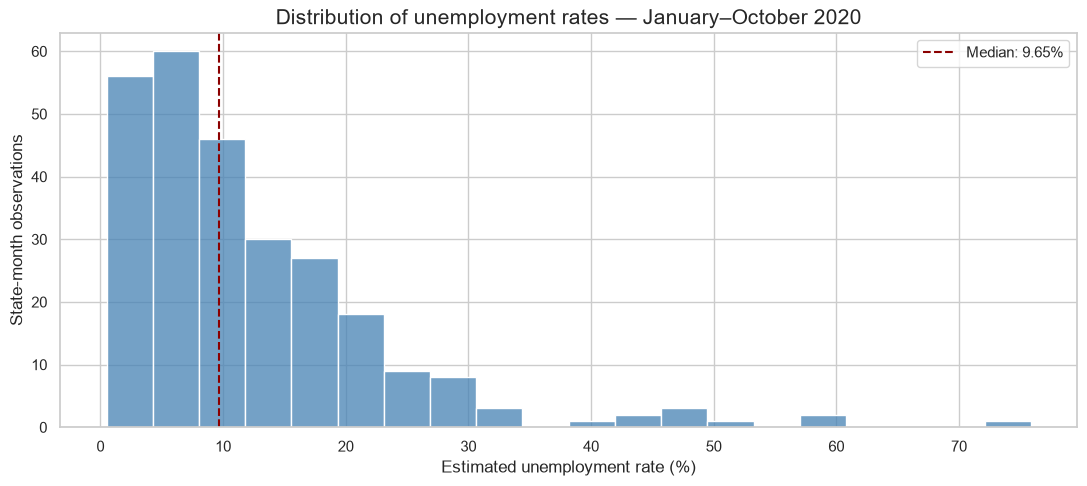

In [5]:
# Chart 1: the distribution of all observed state-month rates.
fig, ax = plt.subplots()
sns.histplot(data=df, x=rate_col, bins=20, color="steelblue", ax=ax)
median_rate = df[rate_col].median()
ax.axvline(median_rate, color="darkred", linestyle="--",
           label=f"Median: {median_rate:.2f}%")
ax.set(title="Distribution of unemployment rates — January–October 2020",
       xlabel="Estimated unemployment rate (%)", ylabel="State-month observations")
ax.legend()
fig.tight_layout()
plt.show()

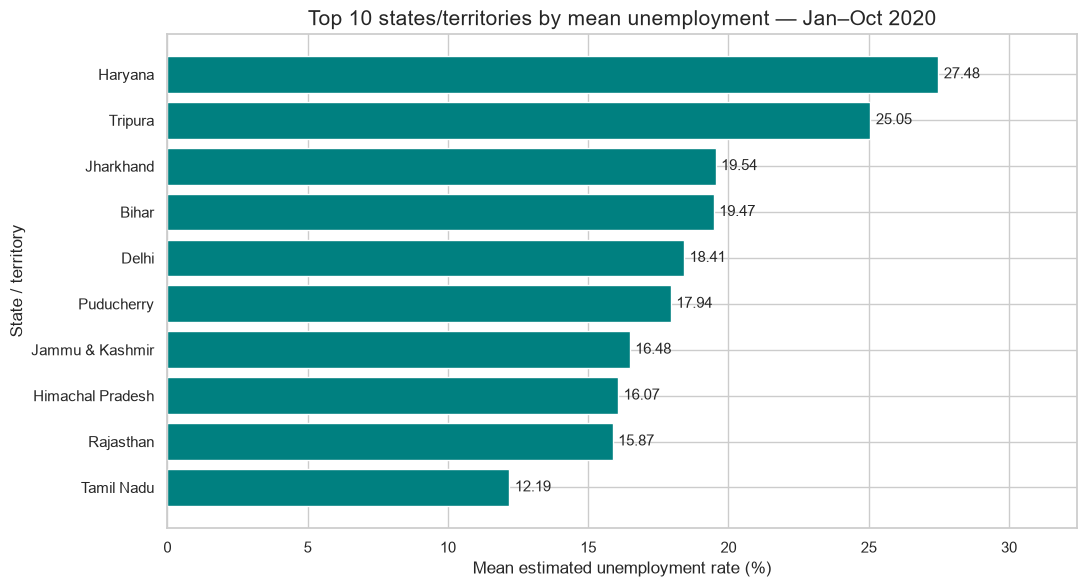

In [6]:
# Chart 2: compare the ten highest state/territory period averages.
top10 = state_summary.head(10).sort_values("mean_unemployment_pct")
fig, ax = plt.subplots(figsize=(11, 6))
ax.barh(top10.index, top10["mean_unemployment_pct"], color="teal")
ax.bar_label(ax.containers[0], fmt="%.2f", padding=4)
ax.set(title="Top 10 states/territories by mean unemployment — Jan–Oct 2020",
       xlabel="Mean estimated unemployment rate (%)", ylabel="State / territory",
       xlim=(0, top10["mean_unemployment_pct"].max() * 1.18))
fig.tight_layout()
plt.show()

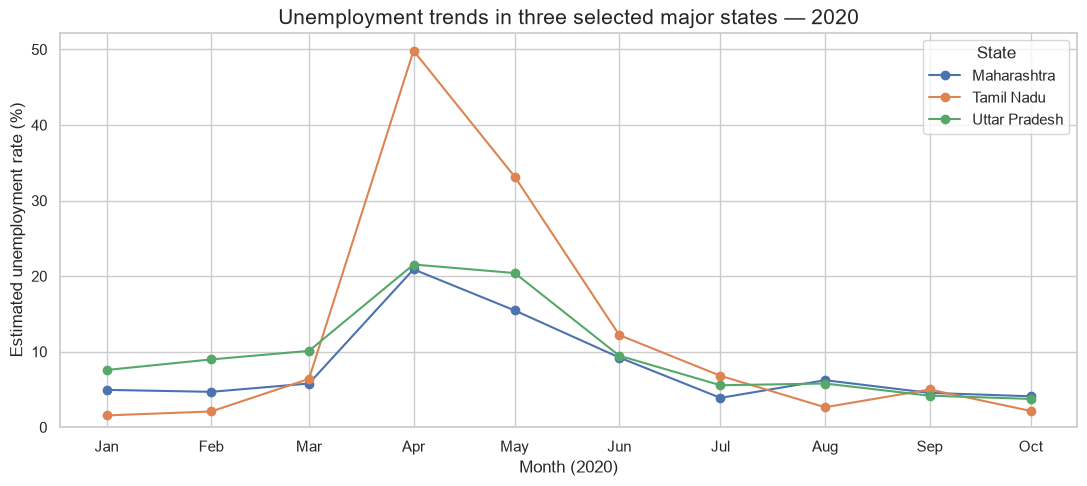

In [7]:
# Chart 3: selected major-state trends (no filling of absent records).
selected_states = ["Maharashtra", "Tamil Nadu", "Uttar Pradesh"]
assert set(selected_states).issubset(df["State"].unique())
state_trends = df.pivot(index="Month", columns="State", values=rate_col)
fig, ax = plt.subplots()
for state in selected_states:
    ax.plot(state_trends.index, state_trends[state], marker="o", label=state)
ax.set(title="Unemployment trends in three selected major states — 2020",
       xlabel="Month (2020)", ylabel="Estimated unemployment rate (%)", ylim=(0, None))
ax.set_xticks(all_months)
ax.set_xticklabels(all_months.strftime("%b"))
ax.legend(title="State")
fig.tight_layout()
plt.show()

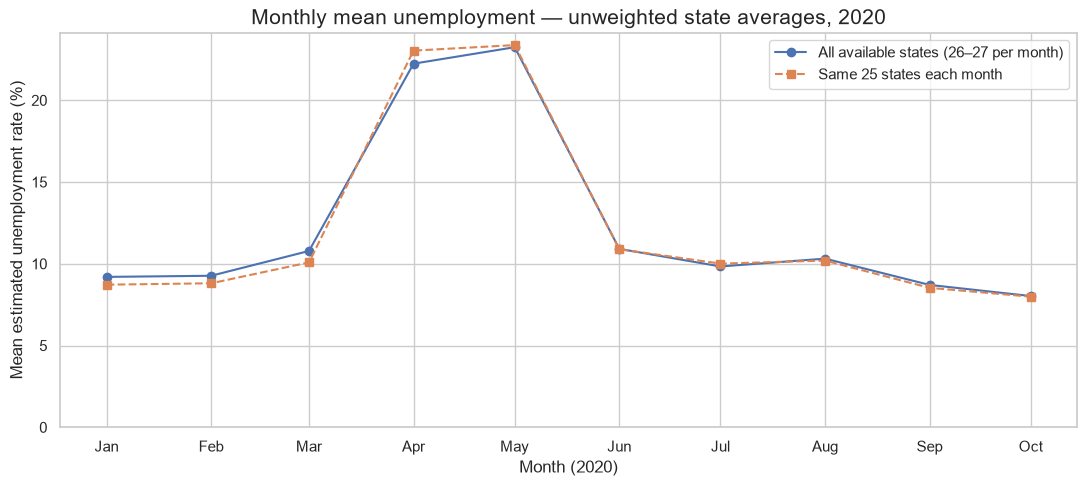

In [8]:
# Chart 4: unweighted monthly means, including a fixed-cohort check.
fig, ax = plt.subplots()
ax.plot(monthly_summary.index, monthly_summary["mean_unemployment_pct"],
        marker="o", label="All available states (26–27 per month)")
ax.plot(monthly_summary.index, monthly_summary["complete_cohort_unemployment_pct"],
        marker="s", linestyle="--", label="Same 25 states each month")
ax.set(title="Monthly mean unemployment — unweighted state averages, 2020",
       xlabel="Month (2020)", ylabel="Mean estimated unemployment rate (%)", ylim=(0, None))
ax.set_xticks(all_months)
ax.set_xticklabels(all_months.strftime("%b"))
ax.legend()
fig.tight_layout()
plt.show()

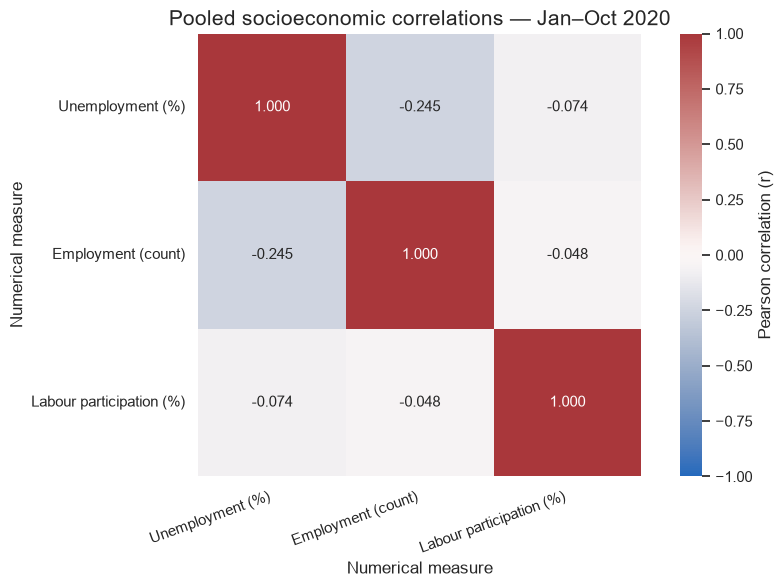

In [9]:
# Chart 5: correlations between the available socioeconomic measures.
short_labels = {rate_col: "Unemployment (%)", employment_col: "Employment (count)",
                participation_col: "Labour participation (%)"}
fig, ax = plt.subplots(figsize=(9, 6))
sns.heatmap(correlation.rename(index=short_labels, columns=short_labels),
            annot=True, fmt=".3f", cmap="vlag", vmin=-1, vmax=1, center=0,
            square=True, cbar_kws={"label": "Pearson correlation (r)"}, ax=ax)
ax.set(title="Pooled socioeconomic correlations — Jan–Oct 2020",
       xlabel="Numerical measure", ylabel="Numerical measure")
ax.set_xticklabels(ax.get_xticklabels(), rotation=20, ha="right")
ax.set_yticklabels(ax.get_yticklabels(), rotation=0)
fig.tight_layout()
plt.show()

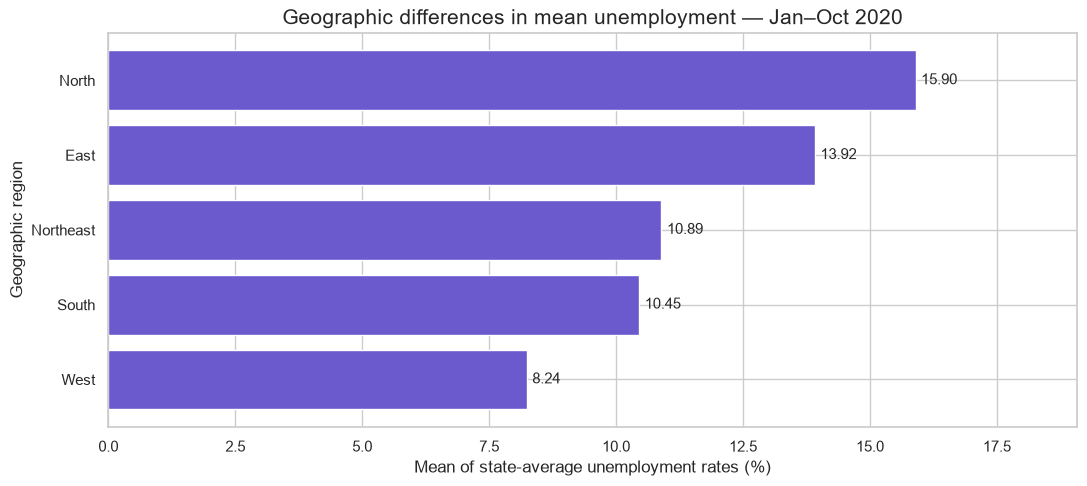

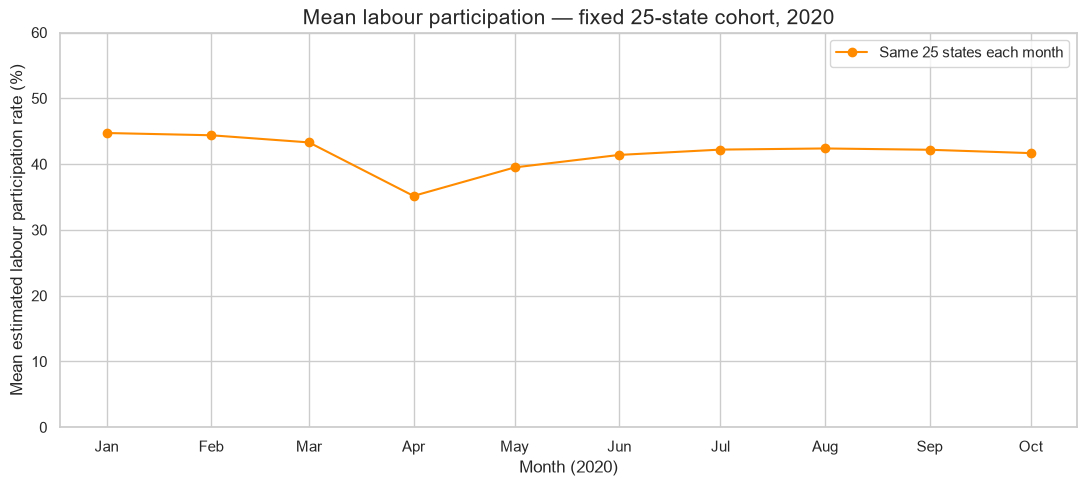

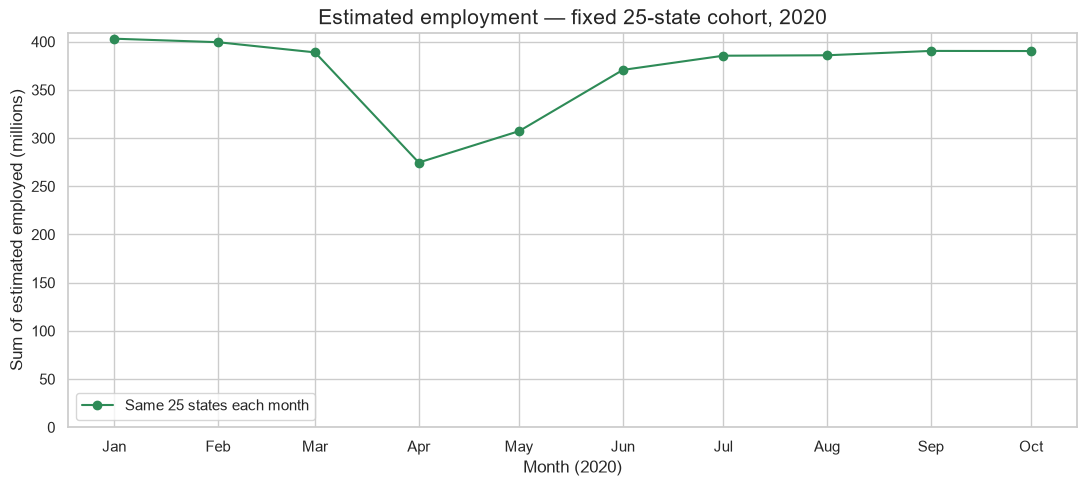

Fixed-cohort participation and employment values:


,mean_participation_pct,sum_estimated_employed
Month,,
2020-01-01,44.72,403114169
2020-02-01,44.38,399471404
2020-03-01,43.30,388921815
2020-04-01,35.16,274609871
2020-05-01,39.50,307259741
2020-06-01,41.39,370726239
2020-07-01,42.20,385462516
2020-08-01,42.38,385909723
2020-09-01,42.18,390429564


In [10]:
# Chart 6: compare broad geographic groups using equal state weights.
region_plot = regional_summary.sort_values("mean_state_unemployment_pct")
fig, ax = plt.subplots()
ax.barh(region_plot.index, region_plot["mean_state_unemployment_pct"], color="slateblue")
ax.bar_label(ax.containers[0], fmt="%.2f", padding=4)
ax.set(title="Geographic differences in mean unemployment — Jan–Oct 2020",
       xlabel="Mean of state-average unemployment rates (%)", ylabel="Geographic region",
       xlim=(0, region_plot["mean_state_unemployment_pct"].max() * 1.2))
fig.tight_layout()
plt.show()

# A fixed cohort supports more comparable monthly participation and employment totals.
cohort_measures = balanced_df.groupby("Month").agg(
    mean_participation_pct=(participation_col, "mean"),
    sum_estimated_employed=(employment_col, "sum"))

# Chart 7: participation is a percentage, not an employment count.
fig, ax = plt.subplots()
ax.plot(cohort_measures.index, cohort_measures["mean_participation_pct"],
        color="darkorange", marker="o", label="Same 25 states each month")
ax.set(title="Mean labour participation — fixed 25-state cohort, 2020",
       xlabel="Month (2020)", ylabel="Mean estimated labour participation rate (%)", ylim=(0, 60))
ax.set_xticks(all_months)
ax.set_xticklabels(all_months.strftime("%b"))
ax.legend()
fig.tight_layout()
plt.show()

# Chart 8: divide estimated counts by one million for readable units.
fig, ax = plt.subplots()
ax.plot(cohort_measures.index, cohort_measures["sum_estimated_employed"] / 1_000_000,
        color="seagreen", marker="o", label="Same 25 states each month")
ax.set(title="Estimated employment — fixed 25-state cohort, 2020",
       xlabel="Month (2020)", ylabel="Sum of estimated employed (millions)", ylim=(0, None))
ax.set_xticks(all_months)
ax.set_xticklabels(all_months.strftime("%b"))
ax.legend()
fig.tight_layout()
plt.show()
print("Fixed-cohort participation and employment values:")
display(cohort_measures.round(2))

## 6. COVID-19-period comparison

### Define the periods before calculating
India's national lockdown was announced on **24 March 2020**, starting at midnight (25 March), according to the [official PIB release](https://www.pib.gov.in/PressReleasePage.aspx?PRID=1608009). Because each record is monthly, March mixes before- and after-lockdown days and is treated separately.

- **Pre-lockdown / pre-COVID-period baseline:** January–February 2020. This is a practical comparison label, **not a claim that there were no COVID-19 cases then**.
- **Transition month:** March 2020; exclude from the primary before/after comparison.
- **COVID-period window:** April–October 2020, the months available after March. This window includes both restriction and reopening phases.
- **Additional descriptive windows:** April–May (early disruption) and June–October (later months).

The primary comparison uses **the same 25 states/territories with all 10 months recorded**. This avoids switching state composition between periods. We also show the all-available-record comparison as a sensitivity check.

**Calculations:**
- Difference in **percentage points (pp)** = COVID-period mean − baseline mean.
- Relative change (%) = difference ÷ baseline mean × 100, only when the baseline is nonzero. Small baselines can produce very large relative changes, so percentage points are generally easier to compare across states.

**Limitations:** Only two baseline months are available, and there is no 2019 comparison or control group. Unequal window lengths, seasonality, survey/measurement changes, other economic events, and incomplete geographic coverage can affect results. A before/after difference does **not** establish how much COVID-19 itself caused unemployment to change. No uncertainty intervals are available from this CSV.

In [11]:
# Label periods using the observed dates; do not infer periods from filenames.
df["Period"] = np.select(
    [df["Date"] < pd.Timestamp("2020-03-01"),
     df["Date"] < pd.Timestamp("2020-04-01")],
    ["Baseline: Jan–Feb", "Transition: March"],
    default="COVID window: Apr–Oct")
balanced_df = df[df["State"].isin(complete_states)].copy()
period_order = ["Baseline: Jan–Feb", "Transition: March", "COVID window: Apr–Oct"]
period_summary = (balanced_df.groupby("Period").agg(
    states=("State", "nunique"), months=("Month", "nunique"),
    observations=(rate_col, "size"), mean_unemployment_pct=(rate_col, "mean"),
    mean_participation_pct=(participation_col, "mean"))
    .reindex(period_order))
print("Primary period summary: fixed 25-state cohort:")
display(period_summary.round(3))

baseline_label, _, covid_label = period_order
baseline_mean = period_summary.loc[baseline_label, "mean_unemployment_pct"]
covid_mean = period_summary.loc[covid_label, "mean_unemployment_pct"]
difference_pp = covid_mean - baseline_mean
relative_change_pct = difference_pp / baseline_mean * 100 if baseline_mean != 0 else np.nan
covid_comparison = pd.DataFrame({"Baseline mean (%)": [baseline_mean],
    "COVID-window mean (%)": [covid_mean], "Difference (pp)": [difference_pp],
    "Relative change (%)": [relative_change_pct]}, index=["Fixed 25-state cohort"])
print("Primary before/after comparison:")
display(covid_comparison.round(3))

all_available_comparison = (df.groupby("Period")[rate_col].mean().reindex(period_order))
print("Sensitivity check: all available state-month observations:")
display(all_available_comparison.rename("Mean unemployment (%)").round(3).to_frame())

window_means = pd.Series({
    "Baseline: Jan–Feb": baseline_mean,
    "Early COVID window: Apr–May": balanced_df.loc[balanced_df["Month"].between("2020-04-01", "2020-05-01"), rate_col].mean(),
    "Later window: Jun–Oct": balanced_df.loc[balanced_df["Month"].between("2020-06-01", "2020-10-01"), rate_col].mean()},
    name="Mean unemployment (%)")
print("More detailed windows: fixed 25-state cohort:")
display(window_means.round(3).to_frame())

# Within-state differences identify variation hidden by the overall comparison.
state_period_means = (balanced_df[balanced_df["Period"].isin([baseline_label, covid_label])]
                      .pivot_table(index="State", columns="Period", values=rate_col, aggfunc="mean"))
state_period_means["Difference (pp)"] = state_period_means[covid_label] - state_period_means[baseline_label]
state_period_means["Relative change (%)"] = (state_period_means["Difference (pp)"]
    .div(state_period_means[baseline_label].replace(0, np.nan)).mul(100))
print("States with the five largest increases (fixed cohort):")
display(state_period_means.sort_values("Difference (pp)", ascending=False).head().round(3))
print("States with the five smallest changes (fixed cohort):")
display(state_period_means.sort_values("Difference (pp)").head().round(3))

Primary period summary: fixed 25-state cohort:


,states,months,observations,mean_unemployment_pct,mean_participation_pct
Period,,,,,
Baseline: Jan–Feb,25,2,50,8.763,44.552
Transition: March,25,1,25,10.082,43.296
COVID window: Apr–Oct,25,7,175,13.431,40.639


Primary before/after comparison:


,Baseline mean (%),COVID-window mean (%),Difference (pp),Relative change (%)
Fixed 25-state cohort,8.763,13.431,4.667,53.26


Sensitivity check: all available state-month observations:


...

,Mean unemployment (%)
Baseline: Jan–Feb,8.763
Early COVID window: Apr–May,23.204
Later window: Jun–Oct,9.521


States with the five largest increases (fixed cohort):


Period,Baseline: Jan–Feb,COVID window: Apr–Oct,Difference (pp),Relative change (%)
State,,,,
Puducherry,1.17,25.126,23.956,2047.497
Tamil Nadu,1.83,15.973,14.143,772.834
Jharkhand,11.23,23.529,12.299,109.515
Bihar,10.45,22.626,12.176,116.514
Goa,5.85,14.960,9.110,155.726


States with the five smallest changes (fixed cohort):


Period,Baseline: Jan–Feb,COVID window: Apr–Oct,Difference (pp),Relative change (%)
State,,,,
Tripura,30.535,22.790,-7.745,-25.364
Chhattisgarh,9.015,7.517,-1.498,-16.615
Himachal Pradesh,16.835,15.460,-1.375,-8.168
Delhi,18.535,18.576,0.041,0.220
Telangana,6.890,6.969,0.079,1.140


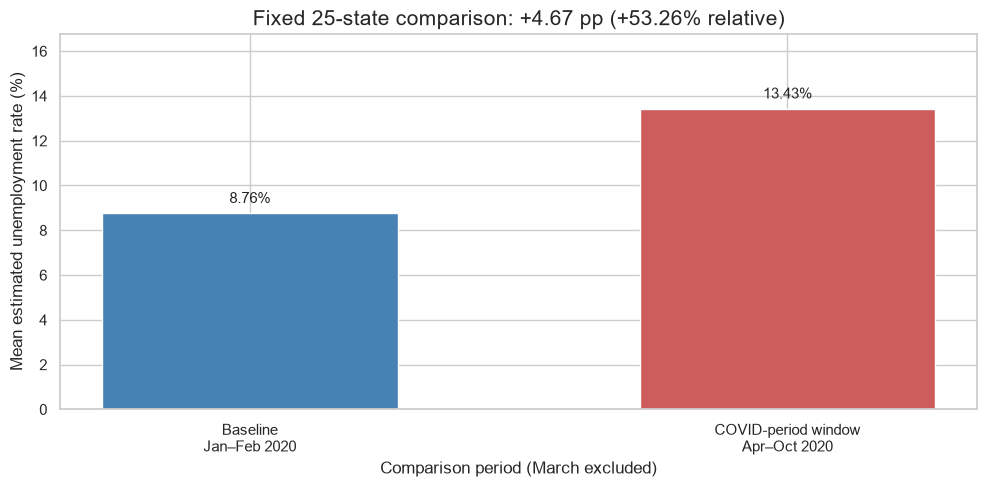

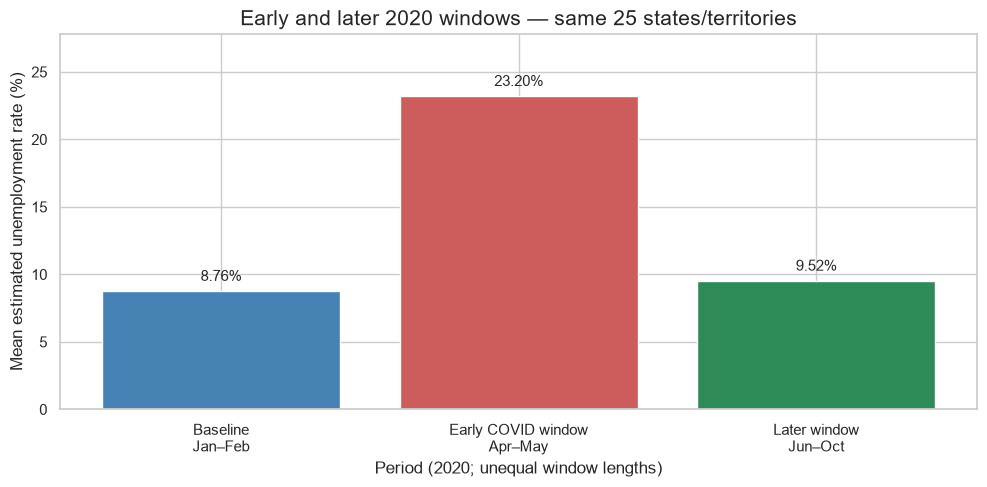

In [12]:
# Chart 9: the explicitly defined primary before/after comparison.
comparison_values = [baseline_mean, covid_mean]
fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(["Baseline\nJan–Feb 2020", "COVID-period window\nApr–Oct 2020"],
       comparison_values, color=["steelblue", "indianred"], width=0.55)
ax.bar_label(ax.containers[0], fmt="%.2f%%", padding=5)
ax.set(title=f"Fixed 25-state comparison: +{difference_pp:.2f} pp (+{relative_change_pct:.2f}% relative)",
       xlabel="Comparison period (March excluded)",
       ylabel="Mean estimated unemployment rate (%)",
       ylim=(0, max(comparison_values) * 1.25))
fig.tight_layout()
plt.show()

# Chart 10: show how an early surge differs from the later-month average.
fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(["Baseline\nJan–Feb", "Early COVID window\nApr–May", "Later window\nJun–Oct"],
       window_means.values, color=["steelblue", "indianred", "seagreen"])
ax.bar_label(ax.containers[0], fmt="%.2f%%", padding=5)
ax.set(title="Early and later 2020 windows — same 25 states/territories",
       xlabel="Period (2020; unequal window lengths)",
       ylabel="Mean estimated unemployment rate (%)",
       ylim=(0, window_means.max() * 1.2))
fig.tight_layout()
plt.show()

In [14]:
# Recheck key values before writing the final observations.
cohort_change = pd.DataFrame({
    "March": [cohort_measures.loc["2020-03-01", "mean_participation_pct"],
              cohort_measures.loc["2020-03-01", "sum_estimated_employed"] / 1_000_000],
    "April": [cohort_measures.loc["2020-04-01", "mean_participation_pct"],
              cohort_measures.loc["2020-04-01", "sum_estimated_employed"] / 1_000_000]},
    index=["Mean participation (%)", "Estimated employed (millions)"])
display(cohort_change.round(3))

# These checks help catch accidentally changed or incomplete source files.
assert len(df) == 267
assert df["State"].nunique() == 27
assert len(all_months) == 10 and len(complete_states) == 25
assert len(missing_records) == 3
assert not df[["State", "Date"] + measure_cols].isna().any().any()
assert np.isclose(difference_pp, covid_mean - baseline_mean)

# pathlib is part of Python's standard library: do not install it separately.
import sys
from importlib.metadata import version
print("Python version:", sys.version.split()[0])
print("JupyterLab version:", version("jupyterlab"))
print("All dataset and calculation checks passed.")

,March,April
Mean participation (%),43.296,35.161
Estimated employed (millions),388.922,274.610


Python version: 3.14.6
JupyterLab version: 4.5.9
All dataset and calculation checks passed.


## 7. Key insights — based on executed results

1. **Overall distribution:** Across 267 observed state-month records, mean unemployment is **12.24%** and the median is **9.65%**. Values range from **0.50% to 75.85%**, indicating a long upper tail. The maximum is Puducherry in April; it was retained rather than removed simply for being extreme.
2. **State differences:** Haryana (**27.48%**) and Tripura (**25.06%**) have the highest observed-month means. Meghalaya (**3.87%**) and Assam (**4.86%**) have the lowest. These are state averages, not population-weighted estimates; Sikkim and Jammu & Kashmir have fewer recorded months.
3. **Geographic differences:** Averaging state-period means equally within groups, **North is highest at 15.90%**, followed by East (**13.92%**), while **West is lowest at 8.24%**. Results depend on the states included and the source's regional grouping.
4. **Monthly pattern:** The all-available-state mean rises to **22.24% in April** and **23.24% in May**, then drops to **10.91% in June** and **8.03% in October**. The fixed 25-state series shows the same broad surge-and-decline pattern, so changing coverage does not explain the pattern by itself.
5. **COVID-period comparison and variation:** For the same 25 states, the January–February baseline is **8.76%**, versus **13.43%** in April–October: **+4.67 percentage points**, or **+53.26% relative**. April–May averages **23.20%**; June–October averages **9.52%**. Changes are not uniform: Puducherry's period difference is **+23.96 pp**, while Tripura's is **−7.75 pp**. These describe timing, not a causal effect of COVID-19.
6. **Participation and estimated employment:** In the fixed cohort, mean participation falls from **43.30% in March to 35.16% in April**. The sum of estimated employed falls from **388.92 million to 274.61 million** over the same months, before rising in later months. These counts describe only the included states and rely on imperfect source unit documentation.
7. **Numerical relationships:** The pooled Pearson correlation between unemployment and estimated employment is **−0.245** (weak negative), and between unemployment and participation is **−0.074** (near-zero linear association). State size, repeated observations, and pooled groups affect these relationships; neither coefficient establishes causation.
8. **Evidence limits:** Dates cover **January–October 2020 only**, with **27 states/territories** and **three missing state-month records**. There is no urban/rural field, 2019 baseline, survey uncertainty, or population weighting. Therefore this notebook cannot establish national unemployment rates, urban/rural differences, or the causal magnitude of the pandemic's effect.

## 8. Final project summary

### Objective
Explore regional differences, monthly unemployment patterns, employment and labour participation estimates, and changes around the 2020 COVID-19 period in India.

### Dataset
Kaggle's **Unemployment in India**, published by **Gokul Raj Kuppan** (version 5), attributed to **CMIE**. The selected CSV contains **267 records and 9 original fields**, covering **27 states/territories in 5 geographic groups**, from **31 January to 31 October 2020**. Each row is a state/territory-month estimate. Dataset redistribution permission is unclear; the CSV stays local and is ignored by Git.

### Tools and libraries
Python, JupyterLab, Pandas, NumPy, Matplotlib, Seaborn, and Python's standard-library Pathlib. No machine-learning model is needed for this descriptive project.

### Cleaning process
Preserved the raw table; trimmed headers and text; clarified duplicated `Region` headers; parsed day-first dates; validated numeric measures, percentage ranges, monthly dates, duplicate keys, and region consistency. No missing-cell imputation or row deletion was needed. Identified absent state-month records and excluded questionable coordinate metadata from the analysis.

### Analyses and visualizations
Calculated overall statistics; ranked states; compared geographic groups; summarized monthly unemployment, participation, and employment; checked a complete 25-state cohort; examined pooled numerical correlations; and compared explicitly defined baseline and COVID-period windows. **Ten charts** cover the distribution, top-10 ranking, three-state trends, monthly averages, correlation heatmap, regional ranking, participation, estimated employment, primary COVID-period comparison, and early-versus-later windows.

### Main findings
The data show large differences between states and a pronounced April–May unemployment surge, accompanied by an April decline in participation and estimated employment. Later-month averages are lower. In the fixed cohort, unemployment rises from **8.76% to 13.43%** between the baseline and April–October windows, but states do not all move in the same direction.

### Limitations and conclusion
This is a short, incomplete, secondary-source dataset with no urban/rural breakdown or uncertainty estimates. Rates are unweighted descriptive summaries, not national estimates. Source employment-unit documentation and coordinate labels require caution. Seasonality, economic conditions, measurement changes, and other factors remain uncontrolled. **The findings document an association in time with the COVID-19 period; they do not prove that COVID-19 alone caused every observed change.**

## Project-review practice — explain the code in your own words

- **Why inspect before cleaning?** To understand real columns, types, missingness, and coverage rather than assume them.
- **Why `copy()`?** To keep the original table available for comparison.
- **Why `pd.to_datetime()`?** Proper dates allow chronological sorting and monthly grouping. The explicit format matches this CSV.
- **What does `groupby().agg()` do?** It groups similar rows and calculates several summaries for each group.
- **Why keep extreme values?** A high rate may be a real estimate; without evidence of an error, deleting it could hide an important pattern.
- **Why not fill missing months with zero?** Zero unemployment is a real value, not a substitute for an unobserved record.
- **Why use the fixed cohort?** The same states in each month make comparisons less sensitive to changing coverage.
- **Percentage points versus percent change?** Here, 13.43 − 8.76 gives about **4.67 pp**; dividing the unrounded difference by the baseline gives **53.26% relative change**.
- **Does correlation prove causation?** No. We have not controlled for state size, time, or other influences.
- **Where is the accuracy score?** This is EDA, not a predictive model, so an accuracy score would be inappropriate.

## 9. GitHub preparation and reproducibility

The final project belongs in **`OIBSIP/DataScience-Task2-UnemploymentAnalysis/`**:

```text
unemployment_analysis.ipynb  # executed code, explanations, tables, and charts
README.md                   # overview, source, setup, findings, limitations
requirements.txt            # tested library versions
.gitignore                  # excludes local data, checkpoints, environments, secrets
dataset/README.md           # download and permission guidance
```

The local `dataset/Unemployment_Rate_upto_11_2020.csv` enables execution but is **ignored by Git** because redistribution permission is unclear. Do not force-add it.

### Reproduce the analysis
1. Read `README.md` and install packages with `python -m pip install -r requirements.txt`.
2. Download the documented source CSV into `dataset/`.
3. Launch JupyterLab from the project folder or repository root and open `unemployment_analysis.ipynb`.
4. Restart the kernel and run all cells in order. A fresh run should reproduce the tables and embedded charts.

### Publish manually when ready
From the local **OIBSIP repository root**, inspect and stage only this project:

```bash
git status --short
git add DataScience-Task2-UnemploymentAnalysis/
git diff --cached --stat
```

Check that no CSV, secret, environment, or unnecessary file is staged. You can then create your own commit and push it when ready. **No commit, push, or automatic GitHub upload was performed.** The existing Task 1 files were not modified.

The source notebook `Untitled7.ipynb` was retained because the new project tab initially failed to connect. The finished project copy is the named notebook above; use that copy for submission. Its final validation checks are based on the documented CSV version, so deliberately changing datasets requires revisiting those checks and the written findings.